# Performance Analysis (DICHASUS)

In [ ]:
import itertools
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import glob
from typing import Optional

import h5py
import pandas as pd
import numpy as np
from matplotlib import rcParams
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as ticker

# ================= Configuration =================
EXP_DIR = './exp/DICHASUS/0152-0157_DirectSample512to32'
TEST_FOLDER = "test"
TEST_DATASET = "0152-0157_DirectSample512to32"

INPUT_CONFIG_LABELS = {
    # '6antx6car': r'6 antennas $\times$ 6 carriers',
    '8antx8car': r'8 antennas $\times$ 8 carriers',
    # '10antx10car': r'10 antennas $\times$ 10 carriers',
    '12antx12car': r'12 antennas $\times$ 12 carriers',
    '16antx16car': r'16 antennas $\times$ 16 carriers',
}

TRAIN_DATA_CONFIG_LABELS = {
    'data36k-nei32': '36,000 training data',
}

MODEL_DIR_NAMES = {
    'ConvCoupler': 'ConvCoupler-d256-dropout',
    'ACoupler': 'ACoupler-d256-dropout_noAgghead1',
    'AFCoupler': 'AFCoupler-d256-dropout',
    'RCDNet': 'RCDNet-d512-dropout',
    'ACDNet': 'ACDNet-d512-dropout',
    # 'AFCDNet': 'AFCDNet_ckpt5w',
    'ConvLSTM': 'ConvLSTM-depth2-ch16',
    'LMMSE': 'LMMSE'
}

# Output directory for figures and CSV files
SAVE_DIR = "./results/DICHASUS-015x"

# ================= Plot style settings =================
plot_config = {
    "font.family": 'Times New Roman',
    "font.size": 14,
    # Keep full axis spines visible.
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.spines.bottom": True,
    "axes.spines.left": True,

    # Tick-direction and tick-size settings.
    "xtick.direction": "in",      # Inward ticks
    "ytick.direction": "in",      # Inward ticks
    "xtick.major.size": 6,        # Major tick length
    "ytick.major.size": 6,
    "xtick.minor.size": 3,        # Minor tick length
    "ytick.minor.size": 3,
    "xtick.minor.visible": True,  # Enable minor ticks
    "ytick.minor.visible": True,

    "xtick.bottom": True,        # Show bottom ticks
    "xtick.top": False,
    "ytick.left": True,          # Show left ticks
    "ytick.right": False,
    # "axes.labelsize": 16,
    # "xtick.labelsize": 14,
    # "ytick.labelsize": 14,
    # "legend.fontsize": 14,
    # "lines.linewidth": 2,
    # "axes.grid": True,
    # "grid.alpha": 0.5,
    # "grid.linestyle": '--'
}
rcParams.update(plot_config)

# Color palette (Set1-like)
# COLORS = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
LINESTYLES = ['-', '--']
MARKERS = ['o', '^', 's', 'd', 'v', 'x']
palette1 = plt.get_cmap('Set1')
palette2 = plt.get_cmap('Pastel1')
linecolors = [palette1(1), palette1(2), palette1(4), palette1(6), palette1(3), palette1(8)]
facecolors = [palette2(1), palette2(2), palette2(4), palette2(5)]


def load_csv(input_config, model_dir_name, task,
             train_data_config: Optional[str]=None):
    """Helper to load a CSV file."""
    if train_data_config is None:
        path = os.path.join(EXP_DIR, f'input_{input_config}', model_dir_name, 'test',
                            TEST_DATASET, 'test', f'{task}.csv')
    else:
        assert isinstance(train_data_config, str)
        path = os.path.join(EXP_DIR, f'input_{input_config}', train_data_config,
                            model_dir_name, 'test', TEST_DATASET, 'test', f'{task}.csv')

    if not os.path.exists(path):
        print(f"⚠️ Warning: File not found: {path}")
        return None
    else:
        return pd.read_csv(path)


def load_and_align_data(input_config, model_name, trace_filename, metric_key,
                        train_data_config: Optional[str]=None):
    """
    Load data and align trajectory with metrics using past_len.
    """
    model_dir_name = MODEL_DIR_NAMES[model_name]
    if train_data_config is None:
        h5_path = os.path.join(EXP_DIR, f'input_{input_config}',
                               model_dir_name, TEST_FOLDER, TEST_DATASET,
                               'trace_smooth', trace_filename)
    else:
        assert isinstance(train_data_config, str)
        h5_path = os.path.join(EXP_DIR, f'input_{input_config}', train_data_config,
                               model_dir_name, TEST_FOLDER, TEST_DATASET,
                               'trace_smooth', trace_filename)

    if not os.path.exists(h5_path):
        raise FileNotFoundError(f"File not found: {h5_path}")

    with h5py.File(h5_path, 'r') as f:
        # Read metadata
        past_len = f.attrs['past_len']
        part_name = f.attrs.get('part_name', 'Unknown Part')
        print(f"[Info] Loading {part_name}, Past Length: {past_len}")

        # 3. Read data
        loc_full = f['loc'][:]    # loc shape: [Total_Len, 3] (x, y, z)
        metric_data = f[metric_key][:]    # metric shape: [Total_Len - Past_Len]

        # 4. Align data
        # metric[0] corresponds to the prediction at loc[past_len].
        # The first past_len steps are warm-up and have no predictions.
        assert len(metric_data) == len(loc_full) - past_len
        loc_aligned = loc_full[past_len:]

    return loc_aligned, metric_data, past_len, part_name


def save_plot(filename):
    """Save figures as PDF/JPG (EPS optional)."""
    os.makedirs(SAVE_DIR, exist_ok=True)
    base = os.path.join(SAVE_DIR, filename)
    plt.savefig(f"{base}.pdf", bbox_inches='tight')
    plt.savefig(f"{base}.jpg", bbox_inches='tight', dpi=300)
    # plt.savefig(f"{base}.eps", bbox_inches='tight')  # Uncomment if EPS is needed.
    print(f"✅ Saved: {base}.pdf/jpg")


def save_csv(df, filename):
    """Save figures as PDF/JPG (EPS optional)."""
    if not filename.endswith('.csv'):
        filename += '.csv'
    os.makedirs(SAVE_DIR, exist_ok=True)
    base = os.path.join(SAVE_DIR, filename)
    df.to_csv(base, index=False)
    print(f"✅ Saved: {base}")


## Boxplots Across Input Sizes and Models

Plotting NMSE Schemes Boxplot (Past Len: 16, Show Outliers: False)...
✅ Saved: ./results/DICHASUS-015x/NMSE_boxplot_schemes_len16.pdf/jpg


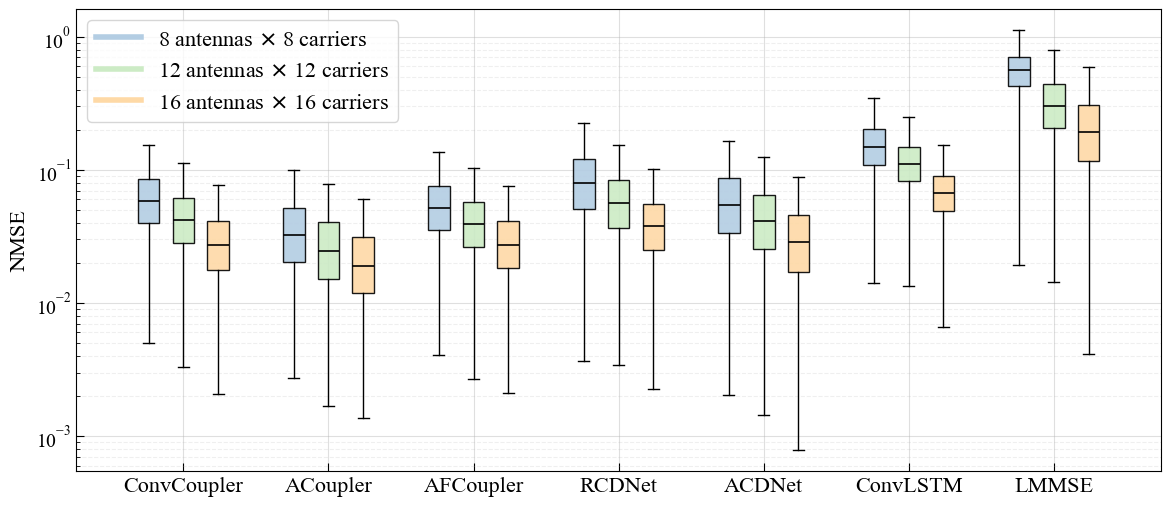


NMSE Statistics Summary (Past Len: 16)
                  Input_Config_Label        Model  Past_Len     Mean  Median (50%)  Q1 (25%)  Q3 (75%)      Min      Max      Std  Count
0     8 antennas $\times$ 8 carriers  ConvCoupler        16 6.92e-02      5.86e-02  3.99e-02  8.55e-02 4.97e-03 8.12e-01 4.63e-02  36000
1     8 antennas $\times$ 8 carriers     ACoupler        16 4.12e-02      3.24e-02  2.03e-02  5.21e-02 2.71e-03 6.68e-01 3.18e-02  36000
2     8 antennas $\times$ 8 carriers    AFCoupler        16 6.05e-02      5.17e-02  3.53e-02  7.57e-02 4.08e-03 6.06e-01 3.86e-02  36000
3     8 antennas $\times$ 8 carriers       RCDNet        16 9.32e-02      7.93e-02  5.04e-02  1.20e-01 3.68e-03 1.88e+00 6.27e-02  36000
4     8 antennas $\times$ 8 carriers       ACDNet        16 6.72e-02      5.49e-02  3.36e-02  8.65e-02 2.04e-03 1.66e+00 5.07e-02  36000
5     8 antennas $\times$ 8 carriers     ConvLSTM        16 1.64e-01      1.48e-01  1.08e-01  2.03e-01 1.42e-02 3.26e+00 8.82e-02  36000
6

In [3]:
def plot_nmse_schemes_boxplot(
        input_configs: list[str], train_data_config: str,
        past_len: int,
        show_outliers: bool = False,
        fig_name: str = "NMSE_boxplot_schemes",
        is_save: bool = True):
    """
    Plot grouped NMSE boxplots across schemes for a fixed past_len.
    """
    # mode_str = "Mixed Scenarios" if is_mix else "Separate Scenarios"
    print(f"Plotting NMSE Schemes Boxplot (Past Len: {past_len}, Show Outliers: {show_outliers})...")

    model_names = list(MODEL_DIR_NAMES.keys())
    stats_results = []  # Store summary statistics

    # --- 1. Define X-axis categories (schemes) ---
    scheme_keys = model_names
    scheme_labels = [model_name for model_name in model_names]

    # --- 2. Prepare plot positions ---
    x = np.arange(len(scheme_keys))
    width = 0.15
    dw = 1.6 * width
    dw_list = (np.arange(len(input_configs)) - (len(input_configs) - 1) / 2) * dw

    plt.figure(figsize=(14, 6))
    plt.yscale('log')

    # --- 3. Collect data and draw per input configuration ---
    for i, input_config in enumerate(input_configs):
        data_for_config = []  # Data for current input_config at all X positions
        input_config_label = INPUT_CONFIG_LABELS[input_config]

        # Iterate over each X-axis scheme
        for key in scheme_keys:
            model_name = key   # key is model_name
            model_dir = MODEL_DIR_NAMES[model_name]

            # Load history_len results and filter by the selected past_len.
            df = load_csv(input_config, model_dir, 'history_len',
                          train_data_config=train_data_config)
            df_filtered = df[df['past_len'] == past_len]
            current_data = df_filtered['nmse'].values
            data_for_config.append(current_data)

            stats_results.append({
                'Input_Config': input_config,
                'Input_Config_Label': input_config_label,
                'Model': model_name,
                'Past_Len': past_len,
                'Count': len(current_data),
                'Mean': np.mean(current_data),
                'Std': np.std(current_data),
                'Min': np.min(current_data),
                'Q1 (25%)': np.percentile(current_data, 25),
                'Median (50%)': np.median(current_data),
                'Q3 (75%)': np.percentile(current_data, 75),
                'Max': np.max(current_data)
            })

        # --- 4. Draw boxplots ---
        positions = x + dw_list[i]

        bp = plt.boxplot(
            data_for_config,
            positions=positions,
            widths=width,
            patch_artist=True,
            showfliers=show_outliers,
            flierprops={
                'marker': 'o', 'markerfacecolor': 'gray', 'markeredgecolor': 'none',
                'markersize': 2, 'alpha': 0.1
            },
            medianprops={'color': 'black', 'linewidth': 1.2}
        )

        # Apply box colors
        for patch in bp['boxes']:
            patch.set_facecolor(facecolors[i])
            patch.set_alpha(0.9)

        plt.plot([], [], color=facecolors[i], label=input_config_label, linewidth=4)

    # --- 5. Styling ---
    plt.xticks(ticks=x, labels=scheme_labels, rotation=0, fontsize=16)
    plt.tick_params(axis='x', which='minor', bottom=False, top=False)
    plt.ylabel(f'NMSE', fontsize=16)
    plt.grid(True, alpha=0.4)
    plt.grid(True, which="major", axis='y', linestyle='-', alpha=0.4)
    plt.grid(True, which="minor", axis='y', linestyle='--', alpha=0.2)
    plt.legend(fontsize=16, loc='upper left')

    final_fig_name = f"{fig_name}_len{past_len}"

    if is_save:
        save_plot(final_fig_name)
    plt.show()
    plt.close()

    # --- Save summary statistics ---
    if stats_results:
        csv_filename = f"{final_fig_name}_stats.csv"
        df_stats = pd.DataFrame(stats_results)

        # Reorder displayed columns
        cols = ['Input_Config_Label', 'Model', 'Past_Len',
                'Mean', 'Median (50%)', 'Q1 (25%)', 'Q3 (75%)',
                'Min', 'Max', 'Std', 'Count']
        cols = [c for c in cols if c in df_stats.columns]
        df_stats = df_stats[cols]

        print("\n" + "="*80)
        print(f"NMSE Statistics Summary (Past Len: {past_len})")
        print("="*80)
        pd.set_option('display.max_rows', None)
        pd.set_option('display.width', 1000)
        pd.set_option('display.float_format', '{:.2e}'.format)
        print(df_stats)
        print("="*80 + "\n")

        if is_save:
            save_csv(df_stats, csv_filename)

# --- Example call ---
input_configs = ['8antx8car', '12antx12car', '16antx16car']
train_data_config = 'data36k-nei32'
target_past_len = 16  # Set the target history length, e.g., 12

plot_nmse_schemes_boxplot(
    input_configs,
    train_data_config,
    past_len=target_past_len,
    is_save=True
)


## NMSE Spatial Distribution: Ideal vs Auto-Regressive

[Info] Loading dichasus-0158, Past Length: 0
✅ Saved: ./results/DICHASUS-015x/trace_heatmap_len0.pdf/jpg


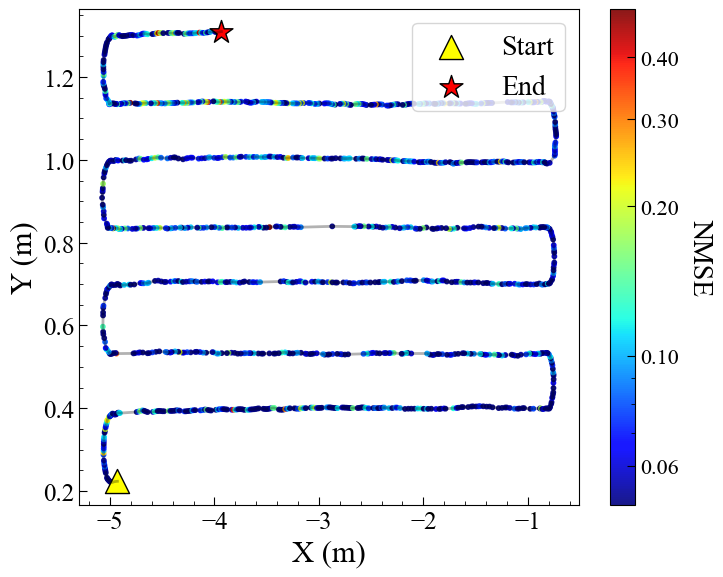

[Info] Loading dichasus-0158, Past Length: 1
✅ Saved: ./results/DICHASUS-015x/trace_heatmap_len1.pdf/jpg


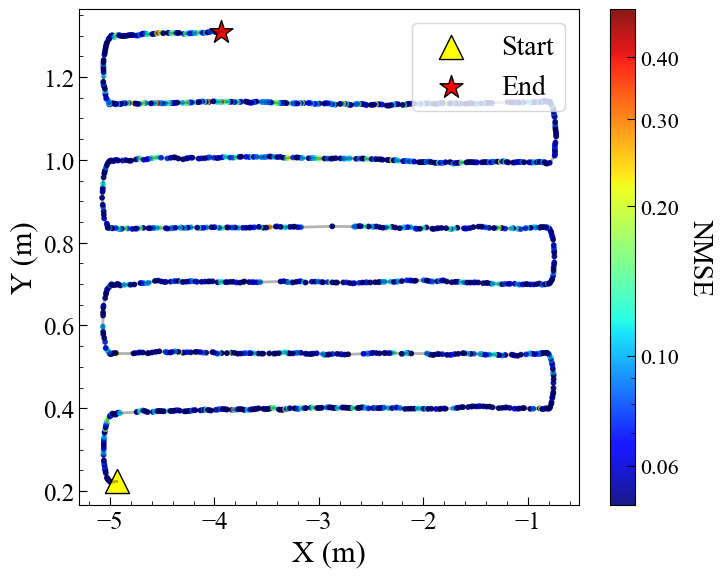

[Info] Loading dichasus-0158, Past Length: 4
✅ Saved: ./results/DICHASUS-015x/trace_heatmap_len4.pdf/jpg


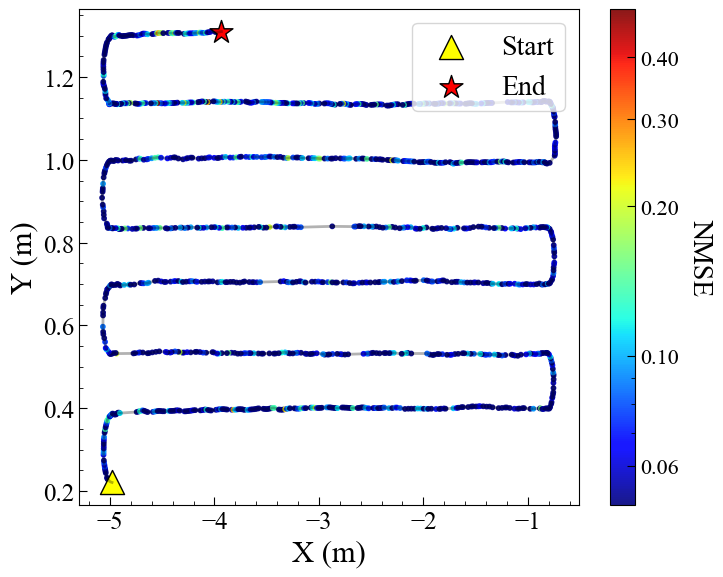

[Info] Loading dichasus-0158, Past Length: 16
✅ Saved: ./results/DICHASUS-015x/trace_heatmap_len16.pdf/jpg


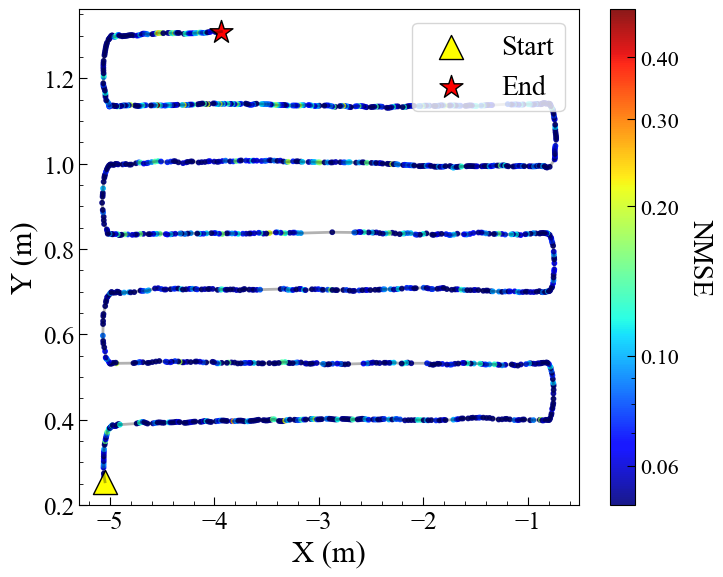

In [61]:
def plot_trajectory(loc, metric, metric_name,
                    fig_name: str = 'trace_heatmap',
                    is_save=None, vmin=None, vmax=None, use_log=True):
    """
    Plot trajectory with color-coded metric values.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib import colors, ticker

    # Extract coordinates
    x = loc[:, 0]
    y = loc[:, 1]

    fig, ax = plt.subplots(figsize=(7.5, 6))

    # 1. Configure colormap normalization
    if use_log:
        if metric.min() <= 0:
            print("[Warning] Data contains <= 0 values; log-scale handling may clamp/filter them.")
            metric = np.maximum(metric, 1e-8)

        if vmin is None:
            vmin = metric.min()
        if vmax is None:
            vmax = metric.max()

        norm = colors.LogNorm(vmin=vmin, vmax=vmax)
    else:
        norm = plt.Normalize(vmin=vmin, vmax=vmax)

    # 2. Trajectory line
    ax.plot(x, y, color='black', alpha=0.3, linewidth=2)

    # 3. Scatter points
    cmap = 'jet'
    sc = ax.scatter(x, y, c=metric, cmap=cmap, norm=norm, s=10, alpha=0.9)

    # 4. Start and end markers
    ax.scatter(x[0], y[0], c='yellow', s=300, marker='^', edgecolors='k', label='Start')
    ax.scatter(x[-1], y[-1], c='red', s=300, marker='*', edgecolors='k', label='End')

    # =========================
    # 5. Configure colorbar
    # =========================
    if use_log:
        # Custom colorbar ticks
        cbar_ticks = [0.06, 0.1, 0.2, 0.3, 0.4]
        cbar = plt.colorbar(sc, ax=ax, ticks=cbar_ticks)

        # Log-style tick labels
        cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
    else:
        cbar = plt.colorbar(sc, ax=ax)

    # Colorbar label font size
    cbar.set_label(f"{metric_name.upper()}", rotation=270, labelpad=25, fontsize=20)

    # Colorbar tick font size
    cbar.ax.tick_params(labelsize=16)

    # =========================
    # 6. Configure axes
    # =========================
    ax.set_xlabel("X (m)", fontsize=22)
    ax.set_ylabel("Y (m)", fontsize=22)
    ax.set_xticks(np.arange(-5.0, -0.5, 1.0))   # Example: -5, -4, -3, -2, -1
    ax.set_yticks(np.arange(0.2, 1.4, 0.2))     # Example: 0.2, 0.4, ..., 1.2
    ax.tick_params(axis='both', which='major', labelsize=18)
    ax.legend(loc='upper right', fontsize=20)

    plt.tight_layout()
    if is_save:
        save_plot(f"{fig_name}")
    plt.show()
    plt.close()

input_config = '8antx8car'
train_data_config = 'data36k-nei32'
model_name_list = ['AFCoupler']
trace_filename_prefix = 'trace_smooth_metrics'
trace_part_name = 'dichasus-0158'
past_len_list = [0, 1, 4, 16]
fig_name = 'trace_heatmap'
schemes = itertools.product(model_name_list, past_len_list)
for (model_name, past_len) in schemes:
    h5_filename = f"{trace_filename_prefix}_{trace_part_name}_pastlen{past_len}.h5"
    loc, metric, past_len, part_name = load_and_align_data(input_config, model_name, h5_filename, 'nmse_list_ar',
                                                           train_data_config=train_data_config)
    plot_trajectory(loc, metric, 'NMSE', fig_name=f"{fig_name}_len{past_len}",
                    is_save=True, vmin=0.05, vmax=0.5)


## NMSE Time Curves: Ideal vs Auto-Regressive

正在对比 Model: AFCoupler 的不同 History Length...
[Info] Loading dichasus-0158, Past Length: 0
[Info] 已添加 LMMSE 对比曲线
[Info] Loading dichasus-0158, Past Length: 0
[Info] Loading dichasus-0158, Past Length: 1
[Info] Loading dichasus-0158, Past Length: 4
[Info] Loading dichasus-0158, Past Length: 16
[Info] Loading dichasus-0158, Past Length: 16
[Info] 已添加 Ideal 参考线 (Source: past_len=16)
✅ Saved: ./results/DICHASUS-015x/NMSE_trace_compare_pastlens_v2.pdf/jpg


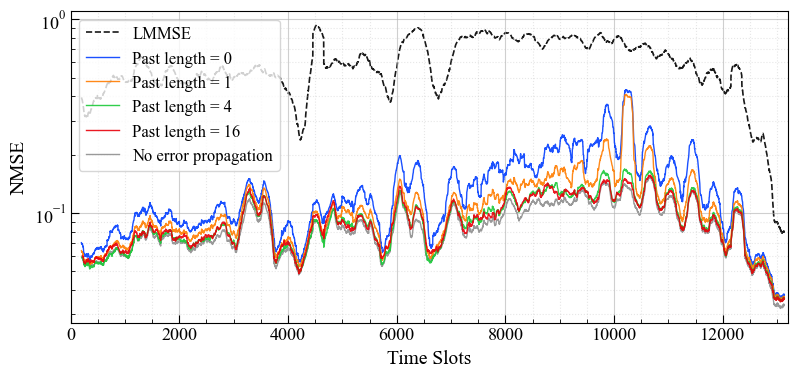

In [57]:
def plot_nmse_lines_comparison(input_config, model_name, train_data_config,
                               trace_filename_prefix, trace_part_name,
                               past_len_list,
                               fig_name='NMSE_trace_compare_pastlens',
                               is_save=None,
                               smooth_window=None,
                               downsample_step=None,
                               ideal_source_past_len=None,
                               include_lmmse=False):
    """
    Plot NMSE-vs-time curves for multiple past_len values (log-scale Y axis).

    Args:
        smooth_window (int): moving-average window; no smoothing if None.
        downsample_step (int): keep one point every N samples for plotting.
        ideal_source_past_len (int): if set, load nmse_list_ideal from that past_len and draw as a gray dashed reference.
        include_lmmse (bool): whether to include LMMSE as an extra reference curve.
    """

    # Initialize figure
    fig, ax = plt.subplots(figsize=(8.2, 4))

    print(f"Comparing different history lengths for model: {model_name}...")

    # Use a seaborn palette
    import seaborn as sns
    palette = sns.color_palette("bright", len(past_len_list))

    # Internal helper to avoid duplicated preprocessing code
    def process_data(metric_data, start_idx):
        # 1. Build raw X axis
        x = np.arange(start_idx, start_idx + len(metric_data))
        y = metric_data

        # 2. Smoothing
        if smooth_window and smooth_window > 1:
            kernel = np.ones(smooth_window) / smooth_window
            y = np.convolve(y, kernel, mode='valid')
            x = x[smooth_window-1:]

        # 3. Downsampling
        if downsample_step and downsample_step > 1:
            x = x[::downsample_step]
            y = y[::downsample_step]

        return x, y

    # --- 2. Plot LMMSE reference ---
    if include_lmmse:
        h5_filename_lmmse = f"{trace_filename_prefix}_{trace_part_name}_pastlen0.h5"
        try:
            _, metric_lmmse, loaded_past_len_lmmse, _ = load_and_align_data(
                input_config, 'LMMSE', h5_filename_lmmse, 'nmse_list_ar', train_data_config=train_data_config
            )

            x_axis_lmmse, plot_data_lmmse = process_data(metric_lmmse, loaded_past_len_lmmse)

            ax.plot(x_axis_lmmse, plot_data_lmmse,
                    label='LMMSE',
                    color='black',
                    linestyle='--',
                    linewidth=1.2,
                    alpha=0.9,
                    zorder=1)

            print("[Info] LMMSE reference curve added.")
        except Exception as e:
            print(f"[Warning] Failed to load LMMSE reference curve: {e}")

    # --- 1. Plot AR (Auto-Regressive) curves ---
    for i, past_len in enumerate(past_len_list):
        h5_filename = f"{trace_filename_prefix}_{trace_part_name}_pastlen{past_len}.h5"

        try:
            _, metric, loaded_past_len, _ = load_and_align_data(
                input_config, model_name, h5_filename, 'nmse_list_ar', train_data_config=train_data_config
            )
        except Exception as e:
            print(f"[Warning] Skipped {past_len}: {e}")
            continue

        x_axis, plot_data = process_data(metric, loaded_past_len)

        ax.plot(x_axis, plot_data,
                label=f'Past length = {past_len}',
                color=palette[i],
                linewidth=1,
                alpha=0.9)

    # --- 3. Plot Ideal (No Error Propagation) reference ---
    if ideal_source_past_len is not None:
        h5_filename_ideal = f"{trace_filename_prefix}_{trace_part_name}_pastlen{ideal_source_past_len}.h5"
        try:
            _, metric_ideal, loaded_past_len_ideal, _ = load_and_align_data(
                input_config, model_name, h5_filename_ideal, 'nmse_list_ideal', train_data_config=train_data_config
            )

            x_axis_ideal, plot_data_ideal = process_data(metric_ideal, loaded_past_len_ideal)

            ax.plot(x_axis_ideal, plot_data_ideal,
                    label='No error propagation',
                    color='gray',
                    linestyle='-',
                    linewidth=1,
                    alpha=0.8,
                    zorder=0)

            print(f"[Info] Ideal reference added (source past_len={ideal_source_past_len}).")
        except Exception as e:
            print(f"[Warning] Failed to load Ideal reference: {e}")

    # --- 4. Configure axes ---
    plt.xlim(0, 13200)
    ax.set_yscale('log')
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))

    # --- 5. Styling ---
    ax.tick_params(axis='both', which='major', labelsize=13)  # X/Y tick font size
    ax.set_xlabel("Time Slots", fontsize=14)
    ax.set_ylabel("NMSE", fontsize=14)

    ax.grid(True, which="major", ls="-", alpha=0.6)
    ax.grid(True, which="minor", ls=":", alpha=0.3)

    ax.legend(loc='upper left', frameon=True, fontsize=12)

    plt.tight_layout()
    if is_save:
        save_plot(f"{fig_name}")
    plt.show()

# ==========================================
# Example run
# ==========================================
input_config = '8antx8car'
train_data_config = 'data36k-nei32'
model_name = 'AFCoupler'
trace_filename_prefix = 'trace_smooth_metrics'
trace_part_name = 'dichasus-0158'
past_len_list = [0, 1, 4, 16]

plot_nmse_lines_comparison(
    input_config, model_name, train_data_config,
    trace_filename_prefix, trace_part_name,
    past_len_list,
    fig_name='NMSE_trace_compare_pastlens_v2',
    is_save=True,
    smooth_window=200,
    ideal_source_past_len=16,
    include_lmmse=True,
)
